In [5]:
# Cell 1: Cài đặt thư viện
!pip install ultralytics huggingface_hub pandas matplotlib seaborn -q

import torch
from ultralytics import YOLO
print("=" * 60)
print(f"[*] PyTorch Version : {torch.__version__}")
print(f"[*] CUDA Available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"[*] GPU Name        : {torch.cuda.get_device_name(0)}")
print("=" * 60)


[*] PyTorch Version : 2.11.0+cu128
[*] CUDA Available  : True
[*] GPU Name        : Tesla T4


In [6]:
# Cell 2 (SỬA LẠI): Tải và chuyển đổi Manga109-s sang chuẩn YOLO
import os
import glob
import time
import zipfile
import shutil
import random
import xml.etree.ElementTree as ET
from pathlib import Path
from huggingface_hub import hf_hub_download

HF_TOKEN = "YOUR_HF_TOKEN_HERE"
REPO_ID = "hal-utokyo/Manga109-s"
ZIP_FILENAME = "Manga109s_released_2026_05_21.zip"

WORK_DIR = Path("/kaggle/working/data")
RAW_DIR = WORK_DIR / "raw"
DATASET_DIR = WORK_DIR / "dataset"
YAML_PATH = WORK_DIR / "manga_text.yaml"

RAW_DIR.mkdir(parents=True, exist_ok=True)

# 1. Tải và giải nén (nếu chưa có)
xml_check = list(RAW_DIR.glob("**/annotations/*.xml"))
if len(xml_check) < 10:
    print("[*] Đang tải dataset Manga109-s từ Hugging Face...")
    zip_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=ZIP_FILENAME,
        repo_type="dataset",
        token=HF_TOKEN,
        local_dir=str(RAW_DIR)
    )
    print("[*] Đang giải nén dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(RAW_DIR)
    print("[✓] Giải nén thành công!")
else:
    print(f"[✓] Dataset raw đã tồn tại ({len(xml_check)} file XML).")

# 2. Tìm thư mục annotations và images
anno_dirs = list(RAW_DIR.glob("**/annotations"))
img_dirs = list(RAW_DIR.glob("**/images"))
annotations_dir = sorted(anno_dirs, key=lambda p: len(p.parts))[0]
images_dir = sorted(img_dirs, key=lambda p: len(p.parts))[0]

print(f"[*] Annotations: {annotations_dir}")
print(f"[*] Images root : {images_dir}")

# 3. Hàm tìm file ảnh thông minh (hỗ trợ cả 000.jpg lẫn 0000.jpg)
def find_image(images_dir, book, idx):
    book_dir = images_dir / book
    if not book_dir.is_dir(): return None
    candidates = [
        f"{idx:03d}.jpg", f"{idx:03d}.png",
        f"{idx:04d}.jpg", f"{idx:04d}.png",
        f"{idx}.jpg", f"{idx}.png"
    ]
    for c in candidates:
        p = book_dir / c
        if p.exists(): return p
    return None

def convert_bbox(xmin, ymin, xmax, ymax, w, h):
    if w <= 0 or h <= 0: return None
    x1, x2 = min(float(xmin), float(xmax)), max(float(xmin), float(xmax))
    y1, y2 = min(float(ymin), float(ymax)), max(float(ymin), float(ymax))
    x1, x2 = max(0.0, min(x1, w)), max(0.0, min(x2, w))
    y1, y2 = max(0.0, min(y1, h)), max(0.0, min(y2, h))
    if x2 <= x1 or y2 <= y1: return None
    xc = (x1 + x2) / (2.0 * w)
    yc = (y1 + y2) / (2.0 * h)
    bw = (x2 - x1) / w
    bh = (y2 - y1) / h
    return 0, round(xc, 6), round(yc, 6), round(bw, 6), round(bh, 6)

train_img = DATASET_DIR / "images" / "train"
val_img = DATASET_DIR / "images" / "val"
train_lbl = DATASET_DIR / "labels" / "train"
val_lbl = DATASET_DIR / "labels" / "val"
for d in [train_img, val_img, train_lbl, val_lbl]:
    d.mkdir(parents=True, exist_ok=True)

xml_files = sorted(list(annotations_dir.glob("*.xml")))
print(f"[*] Đang xử lý {len(xml_files)} tựa truyện Manga...")

all_valid_pages = []
for xml_path in xml_files:
    book_title = xml_path.stem
    tree = ET.parse(xml_path)
    root = tree.getroot()
    pages_node = root.find("pages")
    page_elems = pages_node.findall("page") if pages_node is not None else root.findall("page")
    
    for page in page_elems:
        try:
            pidx = int(page.get("index", 0))
            pw, ph = float(page.get("width")), float(page.get("height"))
        except: continue
        
        src_img = find_image(images_dir, book_title, pidx)
        if src_img is None: continue
        
        labels = []
        for text in page.findall("text"):
            box = convert_bbox(text.get("xmin"), text.get("ymin"), text.get("xmax"), text.get("ymax"), pw, ph)
            if box:
                labels.append(f"{box[0]} {box[1]} {box[2]} {box[3]} {box[4]}\n")
                
        all_valid_pages.append({
            "book": book_title,
            "idx": pidx,
            "src": src_img,
            "labels": labels
        })

print(f"[✓] Tổng số trang truyện hợp lệ: {len(all_valid_pages)}")

# 4. Chia 85% Train / 15% Val và tạo Symlink
random.seed(42)
random.shuffle(all_valid_pages)
val_count = int(len(all_valid_pages) * 0.15)
train_pages = all_valid_pages[val_count:]
val_pages = all_valid_pages[:val_count]

splits = [("train", train_pages, train_img, train_lbl), ("val", val_pages, val_img, val_lbl)]
for s_name, pages, img_d, lbl_d in splits:
    print(f"[*] Đang chuẩn bị tập {s_name} ({len(pages)} trang)...")
    for p in pages:
        stem = f"{p['book']}_{p['idx']:04d}"
        dest_img = img_d / f"{stem}{p['src'].suffix}"
        dest_lbl = lbl_d / f"{stem}.txt"
        
        if not dest_img.exists():
            os.symlink(p['src'].resolve(), dest_img)
            
        with open(dest_lbl, "w") as f:
            f.writelines(p["labels"])

# 5. Ghi file manga_text.yaml
yaml_content = f"""
path: {DATASET_DIR}
train: images/train
val: images/val
nc: 1
names: ['text']
"""
with open(YAML_PATH, "w") as f:
    f.write(yaml_content.strip())

# 6. Kiểm tra lại số lượng ảnh thực tế
n_train = len(list(train_img.glob("*.*")))
n_val = len(list(val_img.glob("*.*")))
print("=" * 60)
print(f"[✓] HOÀN TẤT CHUẨN BỊ DATASET!")
print(f"    - Ảnh Train: {n_train} trang (yêu cầu > 7000)")
print(f"    - Ảnh Val  : {n_val} trang (yêu cầu > 1200)")
print(f"    - File YAML: {YAML_PATH}")
print("=" * 60)


[✓] Dataset raw đã tồn tại (87 file XML).
[*] Annotations: /kaggle/working/data/raw/Manga109s_released_2026_05_21/annotations
[*] Images root : /kaggle/working/data/raw/Manga109s_released_2026_05_21/images
[*] Đang xử lý 87 tựa truyện Manga...
[✓] Tổng số trang truyện hợp lệ: 8519
[*] Đang chuẩn bị tập train (7242 trang)...
[*] Đang chuẩn bị tập val (1277 trang)...
[✓] HOÀN TẤT CHUẨN BỊ DATASET!
    - Ảnh Train: 7242 trang (yêu cầu > 7000)
    - Ảnh Val  : 1277 trang (yêu cầu > 1200)
    - File YAML: /kaggle/working/data/manga_text.yaml


In [7]:
# Cell 3: Huấn luyện YOLOv8n (Mô hình đối chứng)
print("=" * 60)
print("  BẮT ĐẦU HUẤN LUYỆN YOLOv8n (BASELINE)")
print("=" * 60)

model_v8 = YOLO("yolov8n.pt")
results_v8 = model_v8.train(
    data=str(YAML_PATH),
    epochs=30,
    imgsz=640,
    batch=16,
    patience=10,
    seed=0,
    amp=True,
    device=0,
    project="/kaggle/working/runs",
    name="yolov8n_comparison",
    exist_ok=True
)
print("[✓] Huấn luyện YOLOv8n hoàn tất!")


  BẮT ĐẦU HUẤN LUYỆN YOLOv8n (BASELINE)
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data/manga_text.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_compa

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      2.41G     0.9361     0.5793     0.8688        152        640: 100% ━━━━━━━━━━━━ 453/453 5.4it/s 1:240.3sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 3.9it/s 10.2s.2s
                   all       1277      18530      0.953      0.912      0.963      0.758

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      2.41G      0.897     0.5518     0.8609        262        640: 100% ━━━━━━━━━━━━ 453/453 5.4it/s 1:240.3sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 4.1it/s 9.8s0.2s
                   all       1277      18530       0.95      0.911      0.963      0.762

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      2.41G     0.8516       0.52     0.8561        249        640: 100% ━━━━━━━━━━━━ 453/453 5.5it/s 1:230.4sss
                 Class     Ima

In [8]:
# Cell 4: Huấn luyện YOLO11n (Mô hình đề xuất)
print("=" * 60)
print("  BẮT ĐẦU HUẤN LUYỆN YOLO11n (PROPOSED)")
print("=" * 60)

model_v11 = YOLO("yolo11n.pt")
results_v11 = model_v11.train(
    data=str(YAML_PATH),
    epochs=30,
    imgsz=640,
    batch=16,
    patience=10,
    seed=0,
    amp=True,
    device=0,
    project="/kaggle/working/runs",
    name="yolo11n_comparison",
    exist_ok=True
)
print("[✓] Huấn luyện YOLO11n hoàn tất!")


  BẮT ĐẦU HUẤN LUYỆN YOLO11n (PROPOSED)
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data/manga_text.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_compa

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3227.7±1147.6 MB/s, size: 365.2 KB)
val: Scanning /kaggle/working/data/dataset/labels/val.cache... 1277 images, 65 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1277/1277 334.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 80/80 5.9it/s 13.6s0.1s
                   all       1277      18530       0.97      0.946      0.984      0.868
Speed: 1.0ms preprocess, 2.8ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3312.9±976.5 MB/s, size: 352.8 KB)

/tmp/ipykernel_48/1336061412.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_comparison, x="Mô hình", y="mAP@50 (%)", ax=axes[0], palette=["#94a3b8", "#10b981"])
/tmp/ipykernel_48/1336061412.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_comparison, x="Mô hình", y="Parameters (M)", ax=axes[2], palette=["#ef4444", "#8b5cf6"])


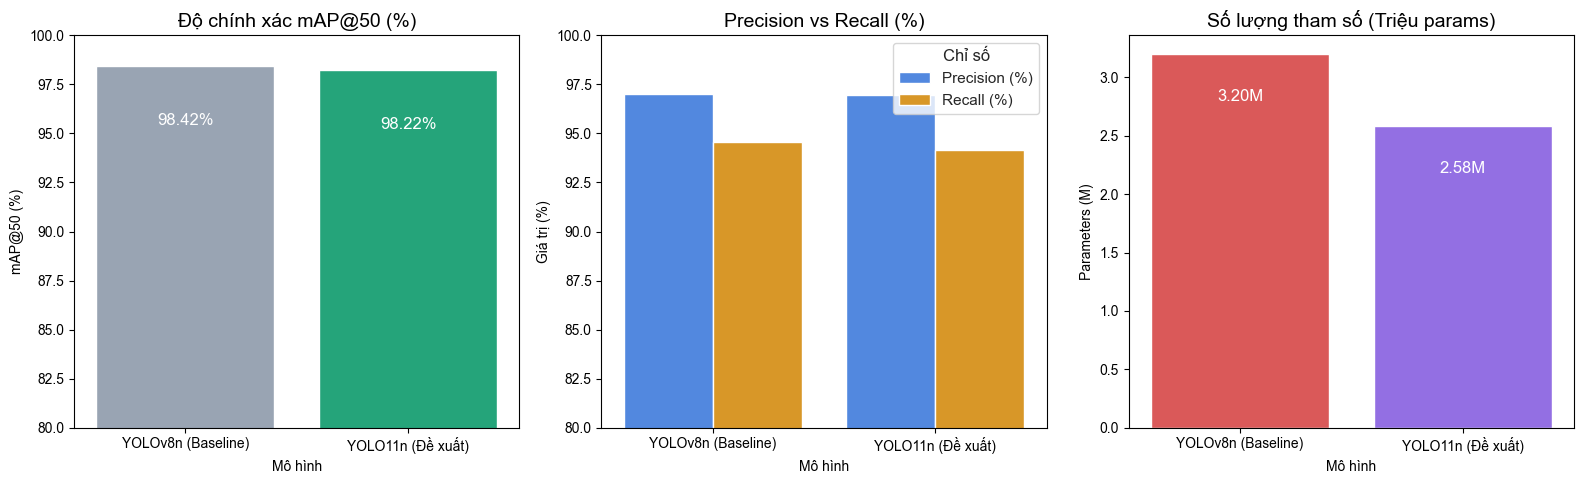


[✓] Đã lưu bảng số liệu: /kaggle/working/model_comparison_results.csv
[✓] Đã lưu biểu đồ so sánh: /kaggle/working/comparison_chart.png


In [9]:
# Cell 5: Trích xuất chỉ số & Vẽ biểu đồ so sánh tự động
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Đánh giá lại trên cùng tập Val
val_v8 = model_v8.val(data=str(YAML_PATH), split="val")
val_v11 = model_v11.val(data=str(YAML_PATH), split="val")

# Thu thập số liệu
data = {
    "Mô hình": ["YOLOv8n (Baseline)", "YOLO11n (Đề xuất)"],
    "mAP@50 (%)": [round(val_v8.box.map50 * 100, 2), round(val_v11.box.map50 * 100, 2)],
    "mAP@50-95 (%)": [round(val_v8.box.map * 100, 2), round(val_v11.box.map * 100, 2)],
    "Precision (%)": [round(val_v8.box.mp * 100, 2), round(val_v11.box.mp * 100, 2)],
    "Recall (%)": [round(val_v8.box.mr * 100, 2), round(val_v11.box.mr * 100, 2)],
    "Inference Latency (ms)": [round(val_v8.speed['inference'], 2), round(val_v11.speed['inference'], 2)],
    "Parameters (M)": [3.2, 2.58]
}

df_comparison = pd.DataFrame(data)
print("\n" + "=" * 70)
print("       BẢNG KẾT QUẢ SO SÁNH ĐỐI CHỨNG (BENCHMARK RESULTS)")
print("=" * 70)
print(df_comparison.to_markdown(index=False))
print("=" * 70)

# Lưu bảng số liệu ra file csv
df_comparison.to_csv("/kaggle/working/model_comparison_results.csv", index=False)

# Vẽ biểu đồ so sánh trực quan
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.set_theme(style="whitegrid")

# 1. So sánh mAP@50
sns.barplot(data=df_comparison, x="Mô hình", y="mAP@50 (%)", ax=axes[0], palette=["#94a3b8", "#10b981"])
axes[0].set_title("Độ chính xác mAP@50 (%)", fontsize=14, fontweight="bold")
axes[0].set_ylim(80, 100)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() - 3),
                     ha='center', color='white', fontweight='bold', fontsize=12)

# 2. So sánh Precision & Recall
df_melt = pd.melt(df_comparison, id_vars=["Mô hình"], value_vars=["Precision (%)", "Recall (%)"], var_name="Chỉ số", value_name="Giá trị (%)")
sns.barplot(data=df_melt, x="Mô hình", y="Giá trị (%)", hue="Chỉ số", ax=axes[1], palette=["#3b82f6", "#f59e0b"])
axes[1].set_title("Precision vs Recall (%)", fontsize=14, fontweight="bold")
axes[1].set_ylim(80, 100)

# 3. So sánh Số lượng tham số (Model Size)
sns.barplot(data=df_comparison, x="Mô hình", y="Parameters (M)", ax=axes[2], palette=["#ef4444", "#8b5cf6"])
axes[2].set_title("Số lượng tham số (Triệu params)", fontsize=14, fontweight="bold")
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.2f}M", (p.get_x() + p.get_width() / 2., p.get_height() - 0.4),
                     ha='center', color='white', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig("/kaggle/working/comparison_chart.png", dpi=300)
plt.show()

print("\n[✓] Đã lưu bảng số liệu: /kaggle/working/model_comparison_results.csv")
print("[✓] Đã lưu biểu đồ so sánh: /kaggle/working/comparison_chart.png")
